# 03 : Train M1 (Text-CNN)

Purpose: build the training vocabulary, train the Text-CNN with the
explicit patience-based early-stopping loop, and show the training curve
and per-epoch metric table. Author: Colile Sibanda.

**Test-set invariant:** this notebook touches `train.csv` and
`validation.csv` only. `test.csv` is loaded in `04_evaluate.ipynb`, once.

In [1]:
import inspect
import os
import subprocess
from datetime import datetime
from pathlib import Path

import pandas as pd

# Notebooks run with the kernel's cwd set to notebooks/; load_config() reads
# a path relative to the repo root, so move up to it first.
_repo_root = Path.cwd()
while not (_repo_root / "pyproject.toml").exists():
    _repo_root = _repo_root.parent
os.chdir(_repo_root)

from phishlens.config.loader import load_config
from phishlens.config.seeding import set_global_seed
from phishlens.evaluation.plots import plot_loss_curve
from phishlens.features.encoder import encode
from phishlens.features.vocabulary import build_vocabulary
from phishlens.models.text_cnn import TextCNN, build_text_cnn, count_parameters
from phishlens.training.batching import make_dataset, make_loader
from phishlens.training.loop import train
from phishlens.training.weighting import positive_class_weight

config = load_config()
set_global_seed(config.seed)
commit_hash = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()

print(f"Config seed: {config.seed}")
print(f"Commit hash: {commit_hash}")
print(f"Run date: {datetime.now().isoformat(timespec='seconds')}")

Config seed: 42
Commit hash: 0e9063658de8fc78dcfb774bc202901b2487d116
Run date: 2026-09-26T10:38:38


## Load the training and validation splits

`test.csv` is never read here : see the invariant above.

In [2]:
processed_dir = Path(config.paths.processed)
train_df = pd.read_csv(processed_dir / "train.csv")
validation_df = pd.read_csv(processed_dir / "validation.csv")

label_column = config.data.label_column

print(f"Train rows: {len(train_df)}")
print(f"Validation rows: {len(validation_df)}")
print(f"Train positive rate: {train_df[label_column].mean():.4f}")
print(f"Validation positive rate: {validation_df[label_column].mean():.4f}")

Train rows: 57736
Validation rows: 12372
Train positive rate: 0.5200
Validation positive rate: 0.5200


## Build the vocabulary

Fitted on training text only : see `src/phishlens/features/vocabulary.py`.
Saved so `04_evaluate.ipynb` and the serving layer encode with the exact
same mapping.

In [3]:
vocabulary = build_vocabulary(train_df["text"].tolist(), config)
vocabulary_path = Path(config.paths.models) / "vocabulary.json"
vocabulary.save(vocabulary_path)

print(f"Vocabulary size: {vocabulary.size()}")
print(f"Vocabulary written to: {vocabulary_path}")

Vocabulary size: 40000
Vocabulary written to: artifacts\models\vocabulary.json


## Encode text and build loaders

In [4]:
train_sequences = encode(train_df["text"].tolist(), vocabulary, config)
validation_sequences = encode(validation_df["text"].tolist(), vocabulary, config)

train_dataset = make_dataset(train_sequences, train_df[label_column].to_numpy())
validation_dataset = make_dataset(validation_sequences, validation_df[label_column].to_numpy())

train_loader = make_loader(train_dataset, config, shuffle=True)
validation_loader = make_loader(validation_dataset, config, shuffle=False)

positive_weight = positive_class_weight(train_df[label_column].to_numpy())
print(f"Positive-class weight (train only): {positive_weight.item():.4f}")

Positive-class weight (train only): 0.9233


## The model class

Printed with `inspect.getsource` so the architecture is readable without
leaving the notebook, per the notebook README.

In [5]:
print(inspect.getsource(TextCNN))

class TextCNN(nn.Module):
    """Text-CNN for binary phishing classification from token ids.

    Architecture: embedding -> parallel 1D convolutions of widths 3, 4 and 5 ->
    ReLU -> max-over-time pooling -> concatenate -> dropout -> linear -> one
    logit. Filter widths act as phrase detectors, which is the argument for a
    CNN on this data: phishing lures are phrases ("verify your account within
    24 hours"). Max-over-time pooling makes the model indifferent to where in
    a long email the lure appears.

    The output is a single logit for use with BCEWithLogitsLoss, not a softmax
    over two classes: numerically steadier, and it keeps the decision
    threshold explicit rather than hidden inside an argmax.

    Inputs: vocab_size : number of vocabulary entries including pad and unk;
    embedding_dim : embedding width; filter_sizes : convolution widths;
    filters_per_size : feature maps per width; dropout : dropout probability
    applied to the pooled features.
    Out

## Build the model

In [6]:
model = build_text_cnn(vocab_size=vocabulary.size(), config=config)
print(f"Trainable parameters: {count_parameters(model):,}")
print(model)

Trainable parameters: 5,274,201
TextCNN(
  (embedding): Embedding(40000, 128, padding_idx=0)
  (convolutions): ModuleList(
    (0): Conv1d(128, 100, kernel_size=(3,), stride=(1,))
    (1): Conv1d(128, 100, kernel_size=(4,), stride=(1,))
    (2): Conv1d(128, 100, kernel_size=(5,), stride=(1,))
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (classifier): Linear(in_features=300, out_features=1, bias=True)
)


## The training loop

Printed with `inspect.getsource` so the patience and best-weight-restore
logic is readable without leaving the notebook.

In [7]:
print(inspect.getsource(train))

def train(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    config: Config,
    *,
    positive_weight: torch.Tensor | None = None,
    device: torch.device | None = None,
    verbose: bool = True,
) -> TrainingResult:
    """Train the model with patience-based early stopping and best-weight restore.

    The loop is deliberately explicit and readable: it is printed into the
    training notebook with inspect.getsource so a reader can check the patience
    logic without leaving the notebook, and the patience is implemented in the
    main loop rather than delegated to a framework callback.

    The behaviour that has to be exactly right:

    1. Patience watches `training.early_stopping.metric` : validation
       macro-F1, not loss. Loss and F1 disagree on imbalanced data and the
       report is written about F1.
    2. A checkpoint is written on every improvement, so the file on disk
       always holds the best epoch's weights.
    3. However the

## Train

In [8]:
result = train(
    model,
    train_loader,
    validation_loader,
    config,
    positive_weight=positive_weight,
    verbose=True,
)

print(f"Best epoch: {result.best_epoch}")
print(f"Best score ({config.training.early_stopping.metric}): {result.best_score:.4f}")
print(f"Epochs run: {result.epochs_run}")
print(f"Stopped early: {result.stopped_early}")
print(f"Checkpoint: {result.checkpoint_path}")

Epoch 1: train_loss 0.1948, val_loss 0.0783, val_macro_f1 0.9707, best 0.9707 at epoch 1, 0/3 without improvement


Epoch 2: train_loss 0.0765, val_loss 0.0441, val_macro_f1 0.9829, best 0.9829 at epoch 2, 0/3 without improvement


Epoch 3: train_loss 0.0416, val_loss 0.0405, val_macro_f1 0.9859, best 0.9859 at epoch 3, 0/3 without improvement


Epoch 4: train_loss 0.0270, val_loss 0.0409, val_macro_f1 0.9862, best 0.9859 at epoch 3, 1/3 without improvement


Epoch 5: train_loss 0.0185, val_loss 0.0524, val_macro_f1 0.9845, best 0.9859 at epoch 3, 2/3 without improvement


Epoch 6: train_loss 0.0137, val_loss 0.0510, val_macro_f1 0.9866, best 0.9859 at epoch 3, 3/3 without improvement
Early stopping: no improvement in val_macro_f1 for 3 epochs. Stopped at epoch 6.
Restored weights: epoch 3
Best epoch: 3
Best score (val_macro_f1): 0.9859
Epochs run: 6
Stopped early: True
Checkpoint: artifacts\models\text_cnn_best.pt


## Training curve

C:\Users\Colile\AppData\Local\Temp\ipykernel_23596\1642627172.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  figure.show()


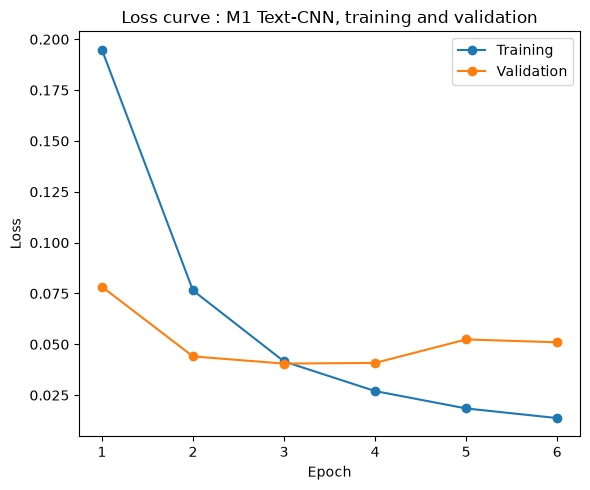

In [9]:
figure = plot_loss_curve(result.history, "M1 Text-CNN")
figure.show()

## Per-epoch metric table

One row per epoch, all train/validation columns : the per-iteration
metric log. Backed by
`artifacts/metrics/training_log.csv`, rewritten every epoch.

In [10]:
history_df = pd.DataFrame(result.history)
history_df

,epoch,train_loss,train_accuracy,train_precision,train_recall,train_f1,train_macro_f1,train_auc_roc,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_macro_f1,val_auc_roc
0,1,0.194846,0.915044,0.921463,0.914557,0.917997,0.914934,0.974897,0.078331,0.970821,0.954219,0.991450,0.972478,0.970715,0.997044
1,2,0.076473,0.970348,0.971486,0.971486,0.971486,0.970300,0.995842,0.044054,0.982945,0.981877,0.985388,0.983629,0.982916,0.998535
2,3,0.041576,0.985174,0.986002,0.985476,0.985739,0.985151,0.998681,0.040523,0.985936,0.982426,0.990673,0.986533,0.985908,0.998827
3,4,0.027019,0.990716,0.991138,0.991006,0.991072,0.990702,0.999391,0.040857,0.986259,0.988610,0.984921,0.986762,0.986239,0.998804
4,5,0.018472,0.993643,0.994101,0.993671,0.993886,0.993633,0.999736,0.052406,0.984481,0.993984,0.976061,0.984941,0.984467,0.998839
5,6,0.013735,0.995150,0.995270,0.995403,0.995337,0.995143,0.999854,0.050998,0.986663,0.991531,0.982745,0.987118,0.986647,0.998761
